# Assignment 2: K-Means Clustering on sales_data_sample.csv (Elbow Method)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.shape)
df.head()

(2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print(df[["QUANTITYORDERED", "PRICEEACH", "SALES"]].isnull().sum())

Duplicate rows: 0
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64


In [4]:
# Select numeric features for clustering
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]].dropna().copy()
X.describe()

,QUANTITYORDERED,PRICEEACH,SALES
count,2823.000000,2823.000000,2823.000000
mean,35.092809,83.658544,3553.889072
std,9.741443,20.174277,1841.865106
min,6.000000,26.880000,482.130000
25%,27.000000,68.860000,2203.430000
50%,35.000000,95.700000,3184.800000
75%,43.000000,100.000000,4508.000000
max,97.000000,100.000000,14082.800000


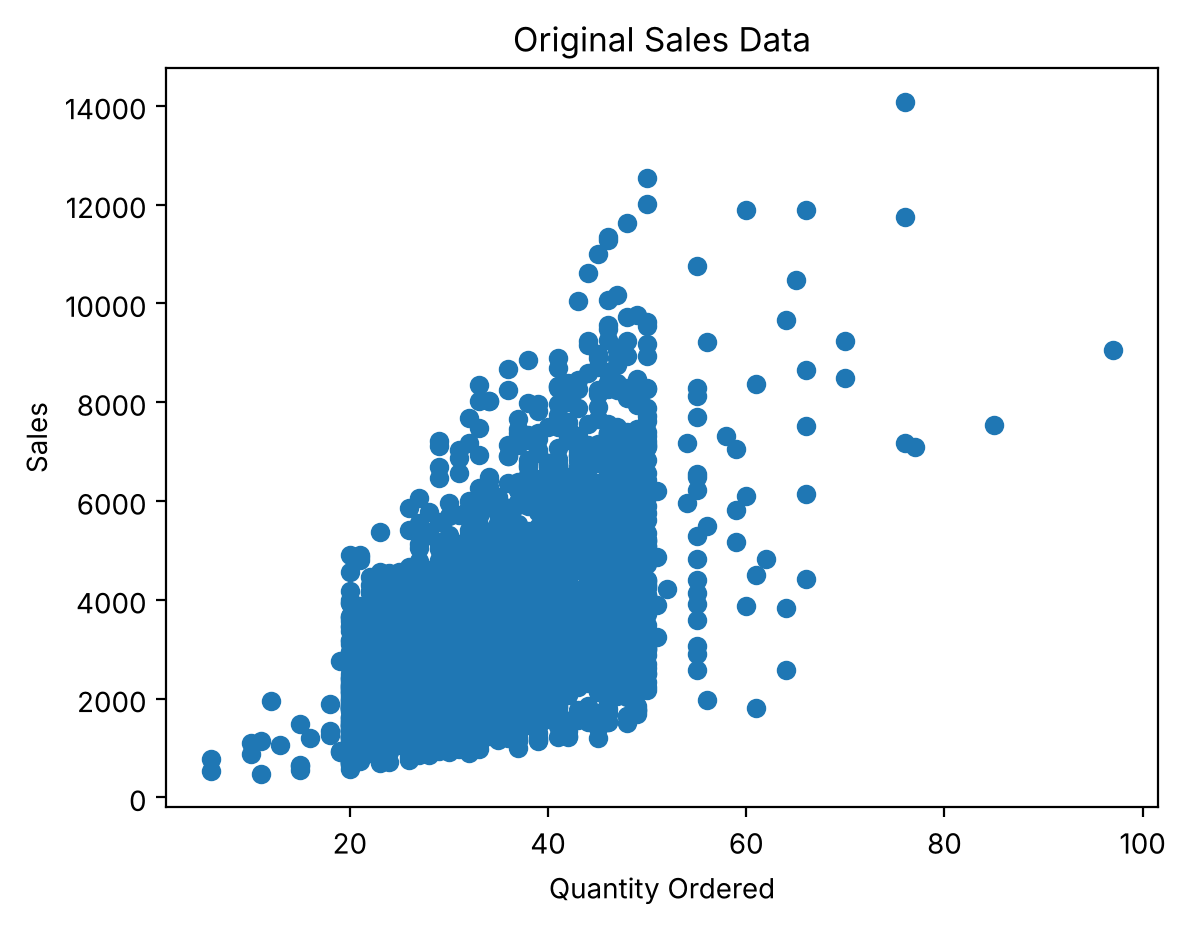

In [5]:
plt.scatter(X["QUANTITYORDERED"], X["SALES"])
plt.xlabel("Quantity Ordered"); plt.ylabel("Sales"); plt.title("Original Sales Data")
plt.show()

In [6]:
# Scale the data (K-Means is distance based)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Elbow method to find the number of clusters

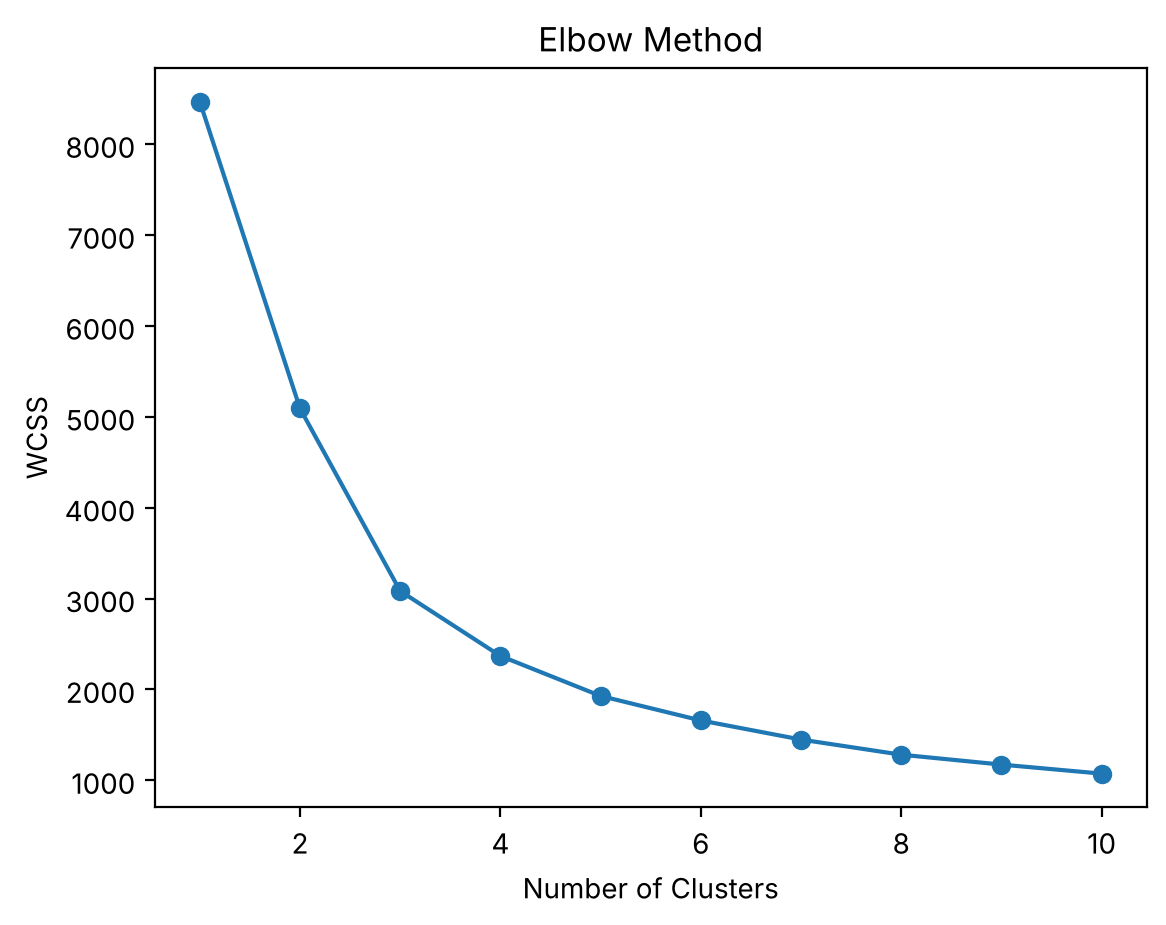

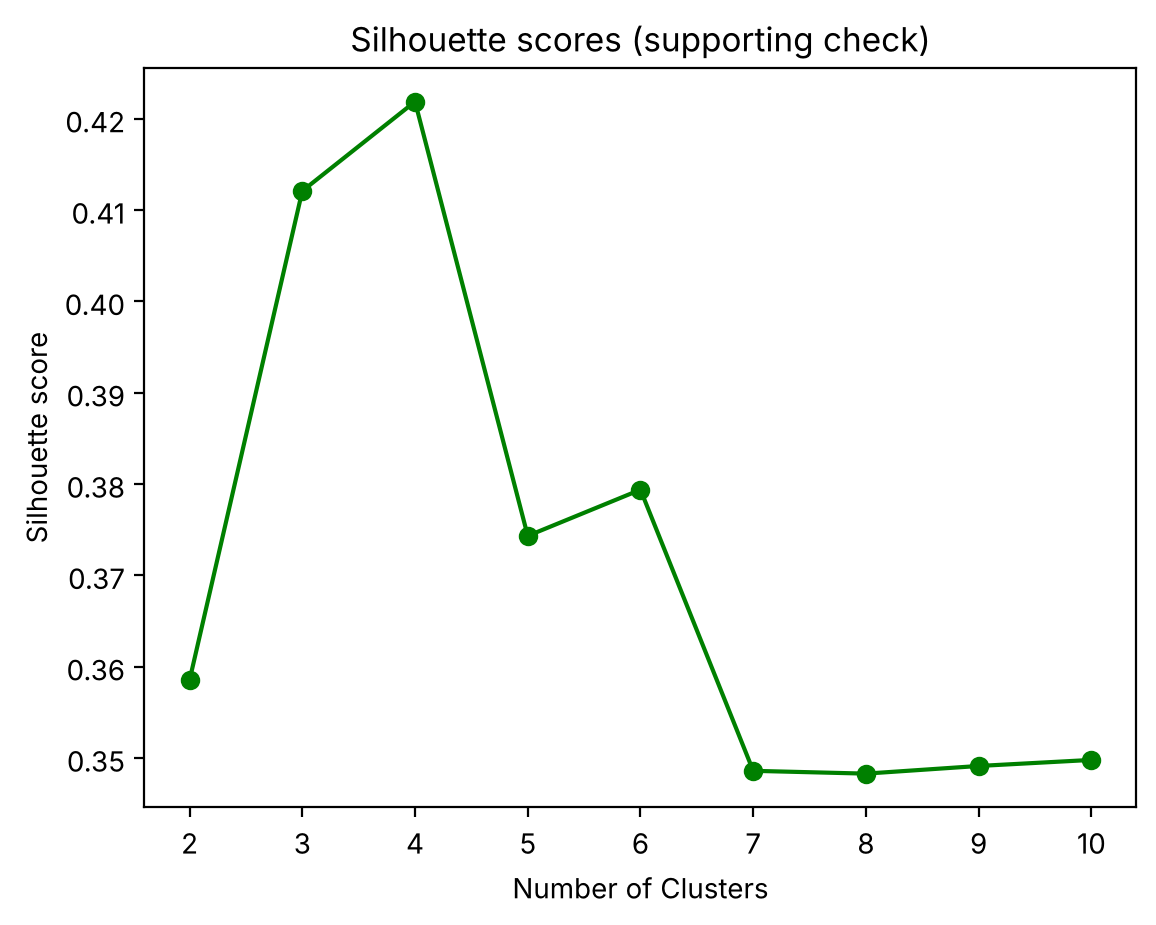

k=2: silhouette=0.359
k=3: silhouette=0.412
k=4: silhouette=0.422
k=5: silhouette=0.374
k=6: silhouette=0.379
k=7: silhouette=0.349
k=8: silhouette=0.348
k=9: silhouette=0.349
k=10: silhouette=0.350


In [7]:
wcss, sil = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    wcss.append(km.inertia_)
    if k > 1:
        sil.append(silhouette_score(X_scaled, km.labels_))

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters"); plt.ylabel("WCSS"); plt.title("Elbow Method")
plt.show()

plt.plot(range(2, 11), sil, marker='o', color='green')
plt.xlabel("Number of Clusters"); plt.ylabel("Silhouette score"); plt.title("Silhouette scores (supporting check)")
plt.show()
for k, s in zip(range(2, 11), sil): print(f"k={k}: silhouette={s:.3f}")

In [8]:
# The elbow bends at k = 4 (WCSS stops dropping sharply after that)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
X["Cluster"] = labels
X.head(10)

,QUANTITYORDERED,PRICEEACH,SALES,Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,0
4,49,100.00,5205.27,1
5,36,96.66,3479.76,2
6,29,86.13,2497.77,2
7,48,100.00,5512.32,1
8,22,98.57,2168.54,2
9,41,100.00,4708.44,1


In [9]:
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=["QUANTITYORDERED", "PRICEEACH", "SALES"])
print("Cluster centres (original units):")
print(centers.round(2))
print("\nRecords in each cluster:")
print(X["Cluster"].value_counts().sort_index())

Cluster centres (original units):
   QUANTITYORDERED  PRICEEACH    SALES
0            43.91      65.83  2877.00
1            43.78      99.12  5938.33
2            27.77      96.48  3218.26
3            28.25      57.00  1587.75

Records in each cluster:
Cluster
0    519
1    751
2    989
3    564
Name: count, dtype: int64


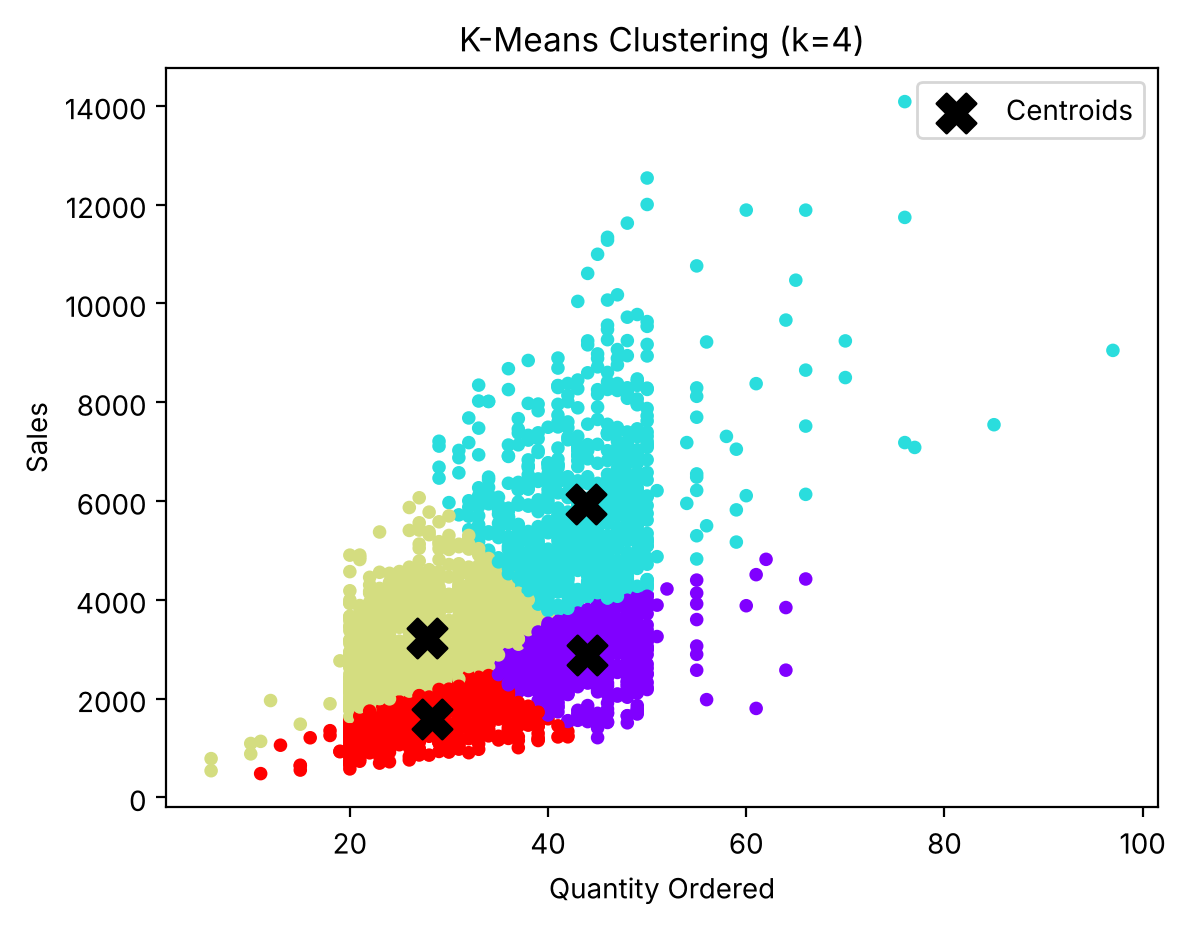

In [10]:
plt.scatter(X["QUANTITYORDERED"], X["SALES"], c=labels, cmap="rainbow", s=15)
plt.scatter(centers["QUANTITYORDERED"], centers["SALES"], c="black", marker="X", s=200, label="Centroids")
plt.xlabel("Quantity Ordered"); plt.ylabel("Sales"); plt.title("K-Means Clustering (k=4)")
plt.legend(); plt.show()

In [11]:
print(X.groupby("Cluster").mean().round(2))

         QUANTITYORDERED  PRICEEACH    SALES
Cluster                                     
0                  43.90      65.78  2874.67
1                  43.79      99.12  5940.23
2                  27.78      96.49  3219.57
3                  28.23      57.02  1587.60
